# Objective 2 — Sales data preprocessing

**Input:** `etech_sales_data.xlsx`, eTech's dated sales receipts from 1 January 2022 to 31 August 2026,
supplied by the shop. On 2 November 2026 it was moved out of `docs/data/` to
`D:/eTech_FYP_archive_2Nov2026/sales_data/`. `docs/data/` keeps the same receipts in the shop's cash-sales layout
(`etech sales data jan2022-aug2026.xlsx`, identical receipt numbers and amounts), but that layout has no dates or
categories, which the weekly series needs, so this notebook reads the archived dated copy.
**Output:** cleaned tables in `ml/data/processed/`, ready for sales prediction and product segmentation.

> **Confidentiality.** Under the agreement signed with the shop owner, nothing produced here may show
> customer personal data, supplier details, cost prices or profit margins. The receipts hold none of them,
> and step 1 checks that before anything else runs.

The workbook has three sheets. **Invoices** is the data: one receipt per row. **Summary** holds the shop's
own totals, used here as a cross-check. **Price Benchmarks** is market price reference and is not used.

Steps:

1. Load the receipts and check they hold no confidential fields
2. Check data quality, and reconcile against the Summary sheet
3. **Remove services** (product sales only, for now)
4. Fix column types
5. Look at outliers
6. Build the **weekly** sales series (and the monthly one, for the report)
7. Engineer forecasting features
8. Split by time into train and test
9. Save the outputs

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Run from ml/ or from the repo root
ROOT = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd().parent
# The dated workbook was archived on 2 Nov 2026 (docs/data keeps the same receipts without dates; see the top cell)
RAW = ROOT.parent / "eTech_FYP_archive_2Nov2026" / "sales_data" / "etech_sales_data.xlsx"
OUT = ROOT / "ml" / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

# Chart style: validated categorical palette (fixed order), recessive axes
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

log = []  # (step, rows, receipts, revenue) - the audit trail for the report
def record(step, frame):
    log.append({"step": step, "rows": len(frame), "receipts": frame["saleId"].nunique(),
                "revenue_RM": round(frame["lineTotal"].sum(), 2)})

## 1. Load the receipts and check for confidential fields

In [2]:
raw = pd.read_excel(RAW, sheet_name="Invoices")
print(raw.shape)
raw.head()

(8542, 20)


,Date,Invoice_No,Product_ID,Product,Brand,Model_Year,Category,Subcategory,CPU,Motherboard,PSU,Cooler,Case,GPU,RAM,SSD,Quantity,Unit_Price_MYR,Invoice_Amount_MYR,Year
0,2022-01-01,CINV-0001-0122,CBL-008,Volex IEC C13 PC Power Cable,Volex,NaN,Cable,Power Cable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,15.0,60.0,2022
1,2022-01-01,CINV-0002-0122,LAP-001,ASUS Zenbook 14 OLED UX3402,ASUS,2022.0,Laptop,Ultrabook,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,4133.0,4133.0,2022
2,2022-01-01,CINV-0003-0122,LAP-002,HP Pavilion Plus 14-eh0000,HP,2022.0,Laptop,Consumer Laptop,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,3803.0,3803.0,2022
3,2022-01-01,CINV-0004-0122,RIG-002,AMD Ryzen 5 5600G Productivity PC Rig,Custom Build,NaN,Complete PC Rig,Productivity PC,AMD Ryzen 5 5600G,MSI B550M PRO-VDH WiFi,Cooler Master MWE 500 Bronze V2,NaN,Tecware Nexus Air M2,NaN,Kingston Fury Beast 16GB DDR4-3200,Kingston NV2 1TB NVMe SSD,1,2820.0,2820.0,2022
4,2022-01-01,CINV-0005-0122,RIG-002,AMD Ryzen 5 5600G Productivity PC Rig,Custom Build,NaN,Complete PC Rig,Productivity PC,AMD Ryzen 5 5600G,MSI B550M PRO-VDH WiFi,Cooler Master MWE 500 Bronze V2,NaN,Tecware Nexus Air M2,NaN,Kingston Fury Beast 16GB DDR4-3200,Kingston NV2 1TB NVMe SSD,3,2930.0,8790.0,2022


In [3]:
# The agreement forbids these kinds of field. Fail loudly if any column looks like one.
FORBIDDEN = ["customer", "name_of", "phone", "email", "address", "supplier",
             "cost", "profit", "margin", "wholesale"]
hits = [c for c in raw.columns if any(f in c.lower() for f in FORBIDDEN)]
assert not hits, f"Confidential columns present: {hits}"
print("Columns:", list(raw.columns))
print("No customer, supplier, cost or margin columns - safe to process.")

Columns: ['Date', 'Invoice_No', 'Product_ID', 'Product', 'Brand', 'Model_Year', 'Category', 'Subcategory', 'CPU', 'Motherboard', 'PSU', 'Cooler', 'Case', 'GPU', 'RAM', 'SSD', 'Quantity', 'Unit_Price_MYR', 'Invoice_Amount_MYR', 'Year']
No customer, supplier, cost or margin columns - safe to process.


The workbook's column names are renamed once, here, to the names the rest of the pipeline uses
(`saleId`, `sku`, `lineTotal` ...). The eight rig-component columns keep their meaning and move to
camel case. `Year` is dropped: it is derived from `Date`, and step 2 checks that it agrees first.

In [4]:
RENAME = {
    "Date": "date", "Invoice_No": "saleId", "Product_ID": "sku", "Product": "itemName",
    "Brand": "brand", "Model_Year": "modelYear", "Category": "category", "Subcategory": "subcategory",
    "Quantity": "quantity", "Unit_Price_MYR": "unitPrice", "Invoice_Amount_MYR": "lineTotal",
    "CPU": "cpu", "Motherboard": "motherboard", "PSU": "psu", "Cooler": "cooler", "Case": "case",
    "GPU": "gpu", "RAM": "ram", "SSD": "ssd",
}
COMPONENTS = ["cpu", "motherboard", "psu", "cooler", "case", "gpu", "ram", "ssd"]
assert set(raw.columns) - set(RENAME) == {"Year"}, set(raw.columns) - set(RENAME)
receipts = raw.rename(columns=RENAME).drop(columns="Year")
record("loaded", receipts)
receipts.columns.tolist()

['date',
 'saleId',
 'sku',
 'itemName',
 'brand',
 'modelYear',
 'category',
 'subcategory',
 'cpu',
 'motherboard',
 'psu',
 'cooler',
 'case',
 'gpu',
 'ram',
 'ssd',
 'quantity',
 'unitPrice',
 'lineTotal']

## 2. Check data quality

In [ ]:
checks = pd.Series({
    "missing date / receipt / product / price": int(receipts[["date", "saleId", "sku", "itemName", "category",
                                                               "quantity", "unitPrice", "lineTotal"]].isna().sum().sum()),
    "duplicate rows": int(raw.duplicated().sum()),
    "duplicate receipt numbers": int(receipts["saleId"].duplicated().sum()),
    "quantity <= 0": int((receipts["quantity"] <= 0).sum()),
    "unitPrice <= 0": int((receipts["unitPrice"] <= 0).sum()),
    "amount != quantity x unit price": int(((receipts["quantity"] * receipts["unitPrice"] - receipts["lineTotal"]).abs() > 0.01).sum()),
    "Year column disagrees with date": int((receipts["date"].dt.year != raw["Year"]).sum()),
    "receipt number suffix (MMYY) disagrees with date": int((receipts["saleId"].str[-4:] != receipts["date"].dt.strftime("%m%y")).sum()),
    "one product ID under two names": int((receipts.groupby("sku")["itemName"].nunique() > 1).sum()),
})
checks.to_frame("problem rows")

,problem rows
missing date / receipt / product / price,0
duplicate rows,0
duplicate receipt numbers,0
quantity <= 0,0
unitPrice <= 0,0
amount != quantity x unit price,0
Year column disagrees with date,0
receipt number suffix (MMYY) disagrees with date,0
one product ID under two names,1


The one product ID under two names is `SRV-009`, a service: *Business PC Setup and Deployment* is also
billed as *(Custom Quote)*. It is the same service priced by quote, and services are removed in step 3,
so nothing needs fixing.

**Blank cells are expected, not missing.** `modelYear` is filled for laptops only, and the component columns
only for complete PC rigs (a rig without a graphics card leaves `gpu` and `cooler` blank). The check below
confirms the blanks follow that rule exactly.

In [6]:
is_rig = receipts["category"].eq("Complete PC Rig")
blanks = pd.Series({
    "rigs missing cpu / motherboard / psu / case / ram / ssd":
        int(receipts.loc[is_rig, ["cpu", "motherboard", "psu", "case", "ram", "ssd"]].isna().any(axis=1).sum()),
    "non-rigs with any component filled": int(receipts.loc[~is_rig, COMPONENTS].notna().any(axis=1).sum()),
    "rigs with a GPU but no cooler, or the reverse": int((receipts.loc[is_rig, "gpu"].isna() != receipts.loc[is_rig, "cooler"].isna()).sum()),
    "laptops without a model year": int(receipts.loc[receipts["category"].eq("Laptop"), "modelYear"].isna().sum()),
    "non-laptops with a model year": int(receipts.loc[~receipts["category"].eq("Laptop"), "modelYear"].notna().sum()),
})
blanks.to_frame("problem rows")

,problem rows
rigs missing cpu / motherboard / psu / case / ram / ssd,0
non-rigs with any component filled,0
"rigs with a GPU but no cooler, or the reverse",0
laptops without a model year,0
non-laptops with a model year,0


In [7]:
print("Date range:", receipts["date"].min().date(), "to", receipts["date"].max().date())
expected = pd.period_range(receipts["date"].min(), receipts["date"].max(), freq="M")
present = receipts["date"].dt.to_period("M").unique()
print(f"Months: {len(present)} of {len(expected)} expected;",
      "none missing" if len(present) == len(expected) else f"missing {sorted(set(expected) - set(present))}")

Date range: 2022-01-01 to 2026-08-31
Months: 56 of 56 expected; none missing


**Reconciliation.** The Summary sheet carries the shop's own totals per year. The receipts must add up to them
exactly, or something was lost or duplicated on the way into the workbook.

In [8]:
summary = pd.read_excel(RAW, sheet_name="Summary", header=None)
start = summary.index[summary[0].eq("Year")][0]
published = (summary.iloc[start + 1:start + 6, 0:4]
                    .set_axis(["year", "revenue", "receipts", "units"], axis=1)
                    .astype({"year": int}).set_index("year").astype(float))
rebuilt = receipts.groupby(receipts["date"].dt.year).agg(
    revenue=("lineTotal", "sum"), receipts=("saleId", "nunique"), units=("quantity", "sum"))
gap = (rebuilt - published).abs()
display(pd.concat({"workbook Summary": published, "rebuilt from receipts": rebuilt}, axis=1).round(2))
assert (gap.max() < 0.01).all(), gap
print("Every year matches the Summary sheet exactly.")

workbook Summary                  rebuilt from receipts               
              revenue receipts   units               revenue receipts units
2022       8300000.00   2246.0  3767.0            8300000.00     2246  3767
2023       7500000.00   2109.0  3486.0            7500000.00     2109  3486
2024       6800000.00   1775.0  2922.0            6800000.00     1775  2922
2025       5900000.00   1557.0  2530.0            5900000.00     1557  2530
2026       3396893.61    855.0  1458.0            3396893.61      855  1458

Every year matches the Summary sheet exactly.


## 3. Remove services

Services (PC assembly, diagnostics, data recovery, network setup) are labour, not stock, and are left out of
sales prediction for now. A service is marked two consistent ways, confirmed below: category `Service` and
product ID prefix `SRV-`.

Every receipt in this workbook holds exactly **one product line**, so removing a service line removes the whole
receipt. There are no mixed receipts to split.

In [9]:
is_service = receipts["category"].eq("Service")
assert is_service.equals(receipts["sku"].str.startswith("SRV-"))
assert receipts["saleId"].is_unique  # one line per receipt

services = receipts[is_service]
print(f"Service receipts removed: {len(services):,} ({len(services)/len(receipts):.1%} of receipts)")
print(f"Service revenue removed: RM {services['lineTotal'].sum():,.2f} "
      f"({services['lineTotal'].sum()/receipts['lineTotal'].sum():.1%} of revenue)")
services.groupby("itemName")["lineTotal"].agg(receipts="count", revenue_RM="sum").sort_values("revenue_RM", ascending=False).round(2)

Service receipts removed: 603 (7.1% of receipts)
Service revenue removed: RM 438,102.61 (1.4% of revenue)


,receipts,revenue_RM
itemName,,
Business PC Setup and Deployment,55,210553.00
Standard Data Recovery Service,72,77417.00
Small Office Network Setup,75,51783.00
Data Transfer and Backup Service,75,23368.00
Business PC Setup and Deployment (Custom Quote),5,15570.61
PC Assembly and Testing,62,15244.00
On-site PC Support,61,14654.00
PC Cleaning and Thermal Service,58,11018.00
Operating System Reinstallation,68,11016.00


In [10]:
sales = receipts[~is_service].copy()
record("services removed", sales)
print(f"{len(sales):,} product receipts remain.")

7,939 product receipts remain.


## 4. Fix column types

In [11]:
sales["period"] = sales["date"].dt.to_period("M")
sales["lineNo"] = 1  # one line per receipt; kept so every table shares the receipt + line key
for col in ["category", "subcategory", "brand"]:
    sales[col] = sales[col].astype("category")
sales["modelYear"] = sales["modelYear"].astype("Int64")
print(sales.dtypes.to_string())

date           datetime64[us]
saleId                    str
sku                       str
itemName                  str
brand                category
modelYear               Int64
category             category
subcategory          category
cpu                       str
motherboard               str
psu                       str
cooler                    str
case                      str
gpu                       str
ram                       str
ssd                       str
quantity                int64
unitPrice             float64
lineTotal             float64
period              period[M]
lineNo                  int64


**Product IDs change at the start of 2026.** Laptops (`LAP-`) keep their IDs across all five years, but every
other product line moves to a new `E`-prefixed ID in January 2026 (`RIG-` becomes `ERIG-`, `CMP-` becomes
`ECMP-`, and so on), with a new list of models behind it. The table counts receipts per ID prefix and year.
The IDs are kept as they are: a product's own history is what segmentation measures, and the category columns
are unchanged, so category-level views still run straight across the change.

In [12]:
prefix = sales["sku"].str.split("-").str[0]
pd.crosstab(prefix, sales["date"].dt.year)

date,2022,2023,2024,2025,2026
sku,,,,,
CBL,104,81,67,67,0
CMP,554,521,392,336,0
ECBL,0,0,0,0,37
ECMP,0,0,0,0,207
EITM,0,0,0,0,37
EPER,0,0,0,0,82
EPRN,0,0,0,0,63
ERIG,0,0,0,0,219
ITM,87,87,70,57,0


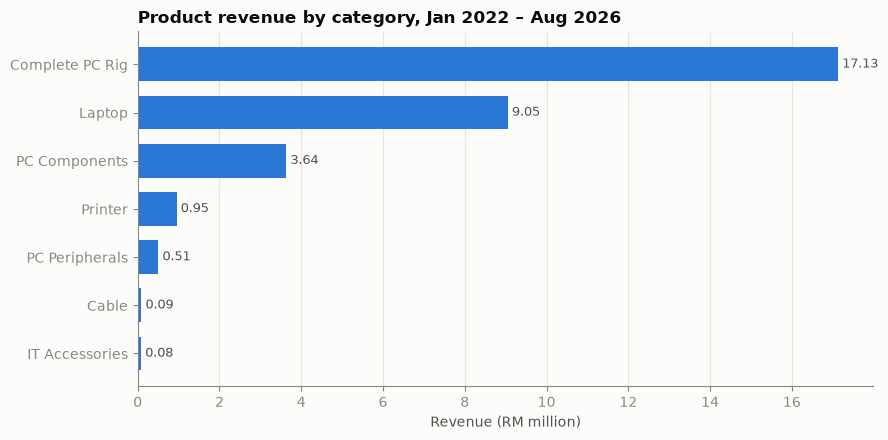

In [13]:
by_cat = sales.groupby("category", observed=True)["lineTotal"].sum().sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(by_cat.index.astype(str), by_cat.values / 1e6, color=BLUE, height=0.7)
ax.grid(axis="x", color=GRID); ax.grid(axis="y", visible=False)
ax.set_title("Product revenue by category, Jan 2022 – Aug 2026")
ax.set_xlabel("Revenue (RM million)")
for y, v in enumerate(by_cat.values / 1e6):
    ax.text(v, y, f" {v:,.2f}", va="center", color=INK_2, fontsize=9)
plt.tight_layout(); plt.show()

## 5. Look at outliers

The only thing that could be an outlier here is a receipt's value. It is checked with the 1.5 × IQR rule
on receipt totals, split into three groups, because a complete PC rig or a laptop is expected to cost many
times a cable or a mouse.

In [14]:
bills = sales[["saleId", "date", "sku", "category", "quantity", "lineTotal"]].rename(columns={"lineTotal": "billTotal"})
bills["group"] = np.select([bills["category"].eq("Complete PC Rig"), bills["category"].eq("Laptop")],
                           ["Complete PC Rig", "Laptop"], "Parts and accessories")

def iqr_flags(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))

bills["isOutlier"] = bills.groupby("group")["billTotal"].transform(iqr_flags)
bills.groupby("group").agg(
    receipts=("saleId", "count"), median_RM=("billTotal", "median"),
    max_RM=("billTotal", "max"), outliers=("isOutlier", "sum")).round(2)

,receipts,median_RM,max_RM,outliers
group,,,,
Complete PC Rig,2152,5748.0,55556.0,127
Laptop,1554,5227.5,22647.0,86
Parts and accessories,4233,596.0,77997.0,387


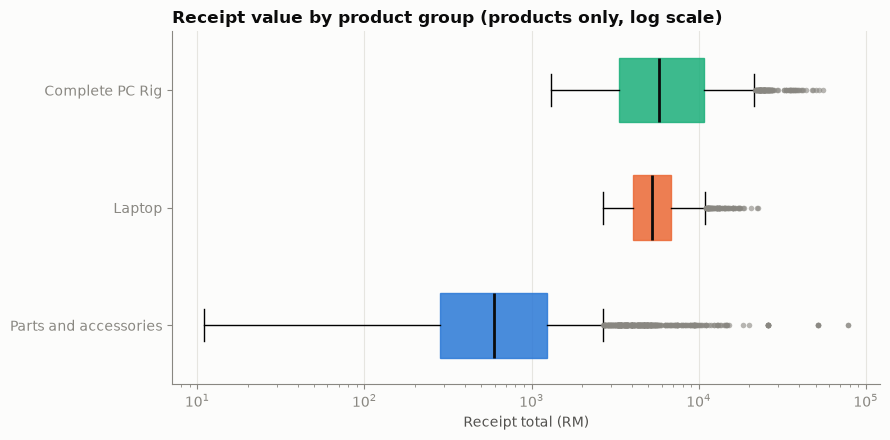

In [15]:
order = ["Parts and accessories", "Laptop", "Complete PC Rig"]
colors = [BLUE, ORANGE, AQUA]
fig, ax = plt.subplots(figsize=(9, 4.5))
parts = ax.boxplot([bills.loc[bills["group"] == o, "billTotal"] for o in order],
                   tick_labels=order, orientation="horizontal", patch_artist=True, widths=0.55,
                   medianprops={"color": INK, "linewidth": 2},
                   flierprops={"marker": "o", "markersize": 4, "markerfacecolor": MUTED,
                               "markeredgecolor": "none", "alpha": 0.6})
for patch, c in zip(parts["boxes"], colors):
    patch.set(facecolor=c, edgecolor=c, alpha=0.85)
ax.set_xscale("log")
ax.grid(axis="x", color=GRID); ax.grid(axis="y", visible=False)
ax.set_title("Receipt value by product group (products only, log scale)")
ax.set_xlabel("Receipt total (RM)")
plt.tight_layout(); plt.show()

In [16]:
# What the flagged receipts are: mostly several units of one product on a single receipt
flagged = bills[bills["isOutlier"]]
print(f"{len(flagged)} flagged receipts; quantity on them:")
flagged["quantity"].value_counts().sort_index().to_frame("receipts").T

600 flagged receipts; quantity on them:


quantity,1,2,3,4
receipts,79,281,188,52


**Decision: keep every outlier.** The flagged receipts are real sales, not errors: the check above shows
what drives them, usually several units of the same product on one receipt (an office buying a batch of
machines or parts). Removing them would teach the model that big sales never happen. The `isOutlier` flag
is saved with the receipt table so a later model can test with and without them.

## 6. Build the weekly sales series

The model is trained on **weekly** sales, not monthly. 56 months leaves only 48 rows to train on, and 36 once
the 12-month lag is taken: enough for a simple trend-and-season model, too few for a machine-learning model to
learn anything but those rows. The same sales summed by week give **243 weeks**.

- A week runs **Monday to Sunday** and belongs to the year its Thursday falls in (ISO 8601), so
  29 Dec 2025 – 4 Jan 2026 is week 1 of 2026.
- The receipts start on Saturday 1 January 2022 and end on Monday 31 August 2026. Those two **partial weeks**
  (two days and one day) are left out of the weekly series, because a one-day "week" would look like a collapse
  in sales. The receipts themselves are kept.
- The **monthly series is still built**. The report's charts are monthly, the shop's sales targets are
  monthly, and a weekly forecast can be summed back into months.

In [17]:
monthly = (sales.groupby("period")
                .agg(bills=("saleId", "nunique"), lines=("lineNo", "count"),
                     units=("quantity", "sum"), revenue=("lineTotal", "sum"))
                .reindex(pd.period_range("2022-01", "2026-08", freq="M"), fill_value=0))
monthly.index.name = "period"
monthly["revenue"] = monthly["revenue"].round(2)
monthly["avgBillValue"] = (monthly["revenue"] / monthly["bills"]).round(2)
assert (monthly["bills"] > 0).all(), "a month with no sales - check before forecasting"
print(len(monthly), "months")
monthly.head(12)

56 months


,bills,lines,units,revenue,avgBillValue
period,,,,,
2022-01,159,159,276,738084.0,4642.04
2022-02,169,169,301,707618.0,4187.09
2022-03,143,143,221,513903.0,3593.73
2022-04,133,133,221,452855.0,3404.92
2022-05,173,173,301,778971.0,4502.72
2022-06,172,172,338,635596.0,3695.33
2022-07,176,176,307,779972.0,4431.66
2022-08,180,180,315,622202.0,3456.68
2022-09,176,176,290,664382.0,3774.90


In [18]:
FIRST_WEEK, LAST_WEEK = pd.Timestamp("2022-01-03"), pd.Timestamp("2026-08-24")  # Mondays of the first and last full week
assert FIRST_WEEK.weekday() == 0 and LAST_WEEK.weekday() == 0
sales["weekStart"] = sales["date"] - pd.to_timedelta(sales["date"].dt.weekday, unit="D")

edge = sales[~sales["weekStart"].between(FIRST_WEEK, LAST_WEEK)]
print(f"Partial weeks left out: {len(edge)} receipts, "
      f"RM {edge['lineTotal'].sum():,.2f}, dated {', '.join(sorted(edge['date'].dt.strftime('%d %b %Y').unique()))}")

weekly = (sales[sales["weekStart"].between(FIRST_WEEK, LAST_WEEK)]
               .groupby("weekStart")
               .agg(bills=("saleId", "nunique"), lines=("lineNo", "count"),
                    units=("quantity", "sum"), revenue=("lineTotal", "sum"))
               .reindex(pd.date_range(FIRST_WEEK, LAST_WEEK, freq="W-MON"), fill_value=0))
weekly.index.name = "weekStart"
weekly["revenue"] = weekly["revenue"].round(2)
weekly["avgBillValue"] = (weekly["revenue"] / weekly["bills"]).round(2)
iso = weekly.index.isocalendar()
weekly.insert(0, "isoYear", iso["year"].astype(int).to_numpy())
weekly.insert(1, "isoWeek", iso["week"].astype(int).to_numpy())
assert (weekly["bills"] > 0).all(), "a week with no sales - check before forecasting"
print(len(weekly), "weeks:", weekly.groupby("isoYear").size().to_dict())
weekly.head()

Partial weeks left out: 12 receipts, RM 102,430.00, dated 01 Jan 2022, 02 Jan 2022, 31 Aug 2026
243 weeks: {2022: 52, 2023: 52, 2024: 52, 2025: 52, 2026: 35}


,isoYear,isoWeek,bills,lines,units,revenue,avgBillValue
weekStart,,,,,,,
2022-01-03,2022,1,40,40,67,205127.0,5128.18
2022-01-10,2022,2,40,40,64,165505.0,4137.62
2022-01-17,2022,3,29,29,49,117810.0,4062.41
2022-01-24,2022,4,34,34,66,139643.0,4107.15
2022-01-31,2022,5,43,43,74,148931.0,3463.51


**What a week can and cannot show.** A weekly series carries the same trend and seasonality as the monthly
one, **with more noise**, because each week rests on far fewer receipts. That noise is the price of four times
the rows. The table below measures it.

In [19]:
m26, w26 = monthly[monthly.index.year == 2026], weekly[weekly["isoYear"] == 2026]
pd.DataFrame({
    "rows": [len(monthly), len(weekly)],
    "mean revenue (RM)": [monthly["revenue"].mean(), weekly["revenue"].mean()],
    "coefficient of variation": [monthly["revenue"].std() / monthly["revenue"].mean(),
                                 weekly["revenue"].std() / weekly["revenue"].mean()],
    "2026: fewest receipts": [m26["bills"].min(), w26["bills"].min()],
    "2026: median receipts": [m26["bills"].median(), w26["bills"].median()],
    "2026: lowest revenue (RM)": [m26["revenue"].min(), w26["revenue"].min()],
}, index=["monthly", "weekly"]).round(2)

,rows,mean revenue (RM),coefficient of variation,2026: fewest receipts,2026: median receipts,2026: lowest revenue (RM)
monthly,56,561764.12,0.24,79,101.5,265839.0
weekly,243,129038.52,0.34,13,23.0,40630.0


In [20]:
# Does the day of the week matter? If it does not, nothing is lost by summing to weeks.
dow = sales.groupby(sales["date"].dt.day_name())["lineTotal"].agg(receipts="count", revenue_RM="sum")
dow.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]).round(0)

,receipts,revenue_RM
date,,
Monday,1083,4545018.0
Tuesday,1162,4167647.0
Wednesday,1097,4024673.0
Thursday,1170,4809654.0
Friday,1143,4616824.0
Saturday,1170,4755384.0
Sunday,1114,4539591.0


In [21]:
# The same series per category, long format - for category-level forecasts later
monthly_category = (sales.groupby(["period", "category"], observed=True)
                         .agg(lines=("lineNo", "count"), units=("quantity", "sum"), revenue=("lineTotal", "sum"))
                         .round(2).reset_index())
monthly_category.head()

,period,category,lines,units,revenue
0,2022-01,Cable,9,49,1881.0
1,2022-01,Complete PC Rig,55,84,486016.0
2,2022-01,IT Accessories,2,3,158.0
3,2022-01,Laptop,30,34,154868.0
4,2022-01,PC Components,39,66,59813.0


In [22]:
yearly = monthly.groupby(monthly.index.year).agg(months=("bills", "size"), receipts=("bills", "sum"), revenue=("revenue", "sum"))
yearly["receiptsPerWeek"] = (weekly.groupby("isoYear")["bills"].mean()).round(1)
yearly["revenuePerMonth"] = (yearly["revenue"] / yearly["months"]).round(2)
yearly["changeVsPrevYear"] = yearly["revenuePerMonth"].pct_change().map(lambda x: f"{x:+.1%}" if pd.notna(x) else "")
yearly

,months,receipts,revenue,receiptsPerWeek,revenuePerMonth,changeVsPrevYear
period,,,,,,
2022,12,2107,8213430.0,40.4,684452.50,
2023,12,1963,7400033.0,37.7,616669.42,-9.9%
2024,12,1636,6671663.0,31.2,555971.92,-9.8%
2025,12,1430,5823308.0,27.5,485275.67,-12.7%
2026,8,803,3350357.0,23.4,418794.62,-13.7%


In [23]:
# Where the decline sits: revenue per month by category, each year against 2022
cat_year = (sales.groupby([sales["date"].dt.year, "category"], observed=True)["lineTotal"].sum()
                 .unstack().div(yearly["months"], axis=0))
(cat_year / cat_year.iloc[0] * 100).round(0).T.rename(columns=lambda y: f"{y} (2022 = 100)")

date,2022 (2022 = 100),2023 (2022 = 100),2024 (2022 = 100),2025 (2022 = 100),2026 (2022 = 100)
category,,,,,
Cable,100.0,96.0,79.0,62.0,154.0
Complete PC Rig,100.0,92.0,87.0,74.0,41.0
IT Accessories,100.0,88.0,66.0,42.0,125.0
Laptop,100.0,90.0,75.0,72.0,58.0
PC Components,100.0,83.0,70.0,53.0,177.0
PC Peripherals,100.0,118.0,92.0,71.0,88.0
Printer,100.0,74.0,74.0,67.0,32.0


**The decline is the shop's own.** Product revenue per month falls in every year of the file, and receipts
per week fall with it. **2026 also changes the mix:** complete rigs, laptops and printers sell well below their
2022 rate, while components, cables and accessories sell above it, in the same months the product range changes
(step 4). That is the series the models in `02_forecasting.ipynb` have to follow, and the table
above shows which categories carry the fall. It also means that the test period (2026) sits below anything in
the training years, which decides which kinds of model can forecast it at all (see `02_forecasting.ipynb`).

## 7. Engineer forecasting features

In [24]:
features = weekly[["isoYear", "isoWeek", "revenue", "bills", "units"]].copy()
features["t"] = np.arange(len(features))                    # trend index: 0 = week of 3 Jan 2022
# Season by the month the week mostly falls in (its Thursday's month).
# 11 month dummies are far easier to fit on ~200 weeks than 51 week-of-year dummies.
thursday = features.index + pd.Timedelta(days=3)
features["month"] = thursday.month
features["quarter"] = thursday.quarter
features = features.join(pd.get_dummies(features["month"], prefix="m", drop_first=True, dtype=int))
# Lags and rolling means use only past weeks (shift first) - no look-ahead leakage.
# 52 weeks back is the same ISO week last year for every year in the file.
features["revenue_lag1"] = features["revenue"].shift(1)
features["revenue_lag52"] = features["revenue"].shift(52)
features["revenue_roll4"] = features["revenue"].shift(1).rolling(4).mean().round(2)
print("Weeks with a missing lag (the first 52 have no lag-52):", int(features["revenue_lag52"].isna().sum()))
features.iloc[50:55]

Weeks with a missing lag (the first 52 have no lag-52): 52


,isoYear,isoWeek,revenue,bills,units,t,month,quarter,m_2,m_3,m_4,m_5,m_6,m_7,m_8,m_9,m_10,m_11,m_12,revenue_lag1,revenue_lag52,revenue_roll4
weekStart,,,,,,,,,,,,,,,,,,,,,,
2022-12-19,2022,51,106479.0,35,50,50,12,4,0,0,0,0,0,0,0,0,0,0,1,206647.0,NaN,166318.00
2022-12-26,2022,52,112198.0,38,56,51,12,4,0,0,0,0,0,0,0,0,0,0,1,106479.0,NaN,153231.50
2023-01-02,2023,1,140910.0,29,43,52,1,1,0,0,0,0,0,0,0,0,0,0,0,112198.0,205127.0,137084.75
2023-01-09,2023,2,86920.0,23,40,53,1,1,0,0,0,0,0,0,0,0,0,0,0,140910.0,165505.0,141558.50
2023-01-16,2023,3,125392.0,34,51,54,1,1,0,0,0,0,0,0,0,0,0,0,0,86920.0,117810.0,111626.75


In [25]:
# The monthly table, kept for comparison and for the report
features_m = monthly[["revenue", "bills", "units"]].copy()
features_m["t"] = np.arange(len(features_m))                # trend index: 0 = Jan 2022
features_m["monthOfYear"] = features_m.index.month
features_m["quarter"] = features_m.index.quarter
features_m = features_m.join(pd.get_dummies(features_m["monthOfYear"], prefix="m", drop_first=True, dtype=int))
features_m["revenue_lag1"] = features_m["revenue"].shift(1)
features_m["revenue_lag12"] = features_m["revenue"].shift(12)
features_m["revenue_roll3"] = features_m["revenue"].shift(1).rolling(3).mean().round(2)
features_m.iloc[10:15]

,revenue,bills,units,t,monthOfYear,quarter,m_2,m_3,m_4,m_5,m_6,m_7,m_8,m_9,m_10,m_11,m_12,revenue_lag1,revenue_lag12,revenue_roll3
period,,,,,,,,,,,,,,,,,,,,
2022-11,858359.0,233,370,10,11,4,0,0,0,0,0,0,0,0,0,1,0,849462.0,NaN,712015.33
2022-12,612026.0,190,286,11,12,4,0,0,0,0,0,0,0,0,0,0,1,858359.0,NaN,790734.33
2023-01,526060.0,128,215,12,1,1,0,0,0,0,0,0,0,0,0,0,0,612026.0,738084.0,773282.33
2023-02,535181.0,119,199,13,2,1,1,0,0,0,0,0,0,0,0,0,0,526060.0,707618.0,665481.67
2023-03,513783.0,134,234,14,3,1,0,1,0,0,0,0,0,0,0,0,0,535181.0,513903.0,557755.67


The first 52 weeks have no `revenue_lag52` (and the first 12 months no `revenue_lag12`). They are **kept** in the
files, not dropped: a trend-plus-season model does not need lags, and a lag model can drop them itself.
Dropping them here would throw away a year of data for every model.

## 8. Split by time into train and test

Time series are split **by date, never randomly**: a random split would let the model train on the future.

- **Train:** ISO weeks 2022-W01 to 2025-W52 (3 Jan 2022 – 28 Dec 2025), 208 weeks, four full years, so every
  month of the year appears four times
- **Test:** ISO weeks 2026-W01 to 2026-W35 (29 Dec 2025 – 30 Aug 2026), the most recent 35 weeks

Week 1 of 2026 holds three days of December 2025, by the ISO rule. The monthly split stays at January 2026:
48 months to train on, 8 to test. (`02_forecasting.ipynb` also re-cuts the same series 80 / 20.)

In [26]:
train = features[features["isoYear"] < 2026]
test = features[features["isoYear"] >= 2026]
print(f"weekly  train: {train.index.min().date()} - {train.index.max().date()}  ({len(train)} weeks)")
print(f"weekly  test:  {test.index.min().date()} - {test.index.max().date()}  ({len(test)} weeks)")
assert len(train) + len(test) == len(features) and train.index.max() < test.index.min()

SPLIT_M = pd.Period("2026-01", freq="M")
train_m = features_m[features_m.index < SPLIT_M]
test_m = features_m[features_m.index >= SPLIT_M]
print(f"monthly train: {train_m.index.min()} - {train_m.index.max()}  ({len(train_m)} months)")
print(f"monthly test:  {test_m.index.min()} - {test_m.index.max()}  ({len(test_m)} months)")
assert len(train_m) + len(test_m) == len(features_m) and train_m.index.max() < test_m.index.min()

weekly  train: 2022-01-03 - 2025-12-22  (208 weeks)


weekly  test:  2025-12-29 - 2026-08-24  (35 weeks)
monthly train: 2022-01 - 2025-12  (48 months)
monthly test:  2026-01 - 2026-08  (8 months)


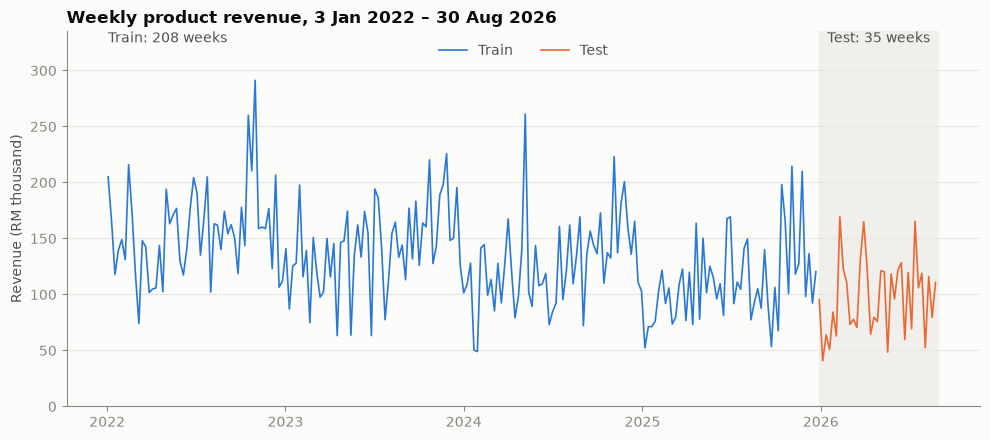

In [27]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(test.index.min(), test.index.max() + pd.Timedelta(days=6), color="#f0efec", zorder=0)
ax.plot(train.index, train["revenue"] / 1e3, color=BLUE, linewidth=1.2, label="Train")
ax.plot(test.index, test["revenue"] / 1e3, color=ORANGE, linewidth=1.2, label="Test")
ax.set_ylim(0, features["revenue"].max() / 1e3 * 1.15)
top = ax.get_ylim()[1]
ax.text(train.index.min(), top, f"Train: {len(train)} weeks", color=INK_2, va="top")
ax.text(test.index.min(), top, f"  Test: {len(test)} weeks", color=INK_2, va="top")
ax.set_title("Weekly product revenue, 3 Jan 2022 – 30 Aug 2026")
ax.set_ylabel("Revenue (RM thousand)")
ax.legend(frameon=False, loc="upper center", ncols=2, labelcolor=INK_2)
plt.tight_layout(); plt.show()

## 9. Save the outputs

Every table is written as a CSV for the modelling notebooks, and the same tables are copied into one Excel
workbook, `etech_sales_preprocessed.xlsx`, for reading and for the report. The workbook is rebuilt on every run,
so it can never disagree with the CSVs.

In [28]:
def save(frame, name, **kw):
    path = OUT / name
    frame.to_csv(path, **kw)
    print(f"{name:<32} {len(frame):>6,} rows")

ymd = lambda d: d.strftime("%Y-%m-%d")
LINE_COLUMNS = ["saleId", "lineNo", "date", "period", "weekStart", "sku", "itemName", "category", "subcategory",
                "brand", "modelYear", "quantity", "unitPrice", "lineTotal"] + COMPONENTS
lines_out = sales[LINE_COLUMNS].assign(date=sales["date"].dt.strftime("%Y-%m-%d"), period=sales["period"].astype(str),
                                       weekStart=sales["weekStart"].dt.strftime("%Y-%m-%d"))
save(lines_out, "sales_lines_products.csv", index=False)
save(bills.assign(date=bills["date"].dt.strftime("%Y-%m-%d")), "bills_products.csv", index=False)
save(weekly.rename(index=ymd), "weekly_product_sales.csv")
save(train.rename(index=ymd), "train_weekly.csv")
save(test.rename(index=ymd), "test_weekly.csv")
save(monthly.rename(index=str), "monthly_product_sales.csv")
save(monthly_category.assign(period=monthly_category["period"].astype(str)), "monthly_category_sales.csv", index=False)
save(train_m.rename(index=str), "train_monthly.csv")
save(test_m.rename(index=str), "test_monthly.csv")

# Last guard: nothing written may carry a confidential field
for f in OUT.glob("*.csv"):
    cols = pd.read_csv(f, nrows=0).columns
    assert not [c for c in cols if any(w in c.lower() for w in FORBIDDEN)], f
print("\nNo confidential columns in any output.")

sales_lines_products.csv          7,939 rows
bills_products.csv                7,939 rows
weekly_product_sales.csv            243 rows
train_weekly.csv                    208 rows
test_weekly.csv                      35 rows
monthly_product_sales.csv            56 rows
monthly_category_sales.csv          388 rows
train_monthly.csv                    48 rows
test_monthly.csv                      8 rows

No confidential columns in any output.


In [29]:
from openpyxl.utils import get_column_letter

XLSX = OUT / "etech_sales_preprocessed.xlsx"
sheets = {  # sheet name -> (table, what it is)
    "weekly":           (weekly.reset_index(), f"Product sales per ISO week (Mon-Sun), {len(weekly)} full weeks - the modelling series"),
    "train_weekly":     (train.reset_index(), f"Weekly features, 2022-W01 to 2025-W52 ({len(train)} weeks)"),
    "test_weekly":      (test.reset_index(), f"Weekly features, 2026-W01 to 2026-W35 ({len(test)} weeks)"),
    "monthly":          (monthly.rename(index=str).reset_index(), f"Product sales per month, Jan 2022 - Aug 2026 ({len(monthly)} months)"),
    "train_monthly":    (train_m.rename(index=str).reset_index(), f"Monthly features, Jan 2022 - Dec 2025 ({len(train_m)} months)"),
    "test_monthly":     (test_m.rename(index=str).reset_index(), f"Monthly features, Jan 2026 - Aug 2026 ({len(test_m)} months)"),
    "monthly_category": (monthly_category.assign(period=monthly_category["period"].astype(str)), "Product sales per month per category"),
    "bills":            (bills, "One row per receipt, products only, with the isOutlier flag"),
    "sales_lines":      (lines_out, "Every product receipt after services were removed"),
}
for name, (frame, _) in sheets.items():  # the same confidentiality guard as the CSVs
    assert not [c for c in frame.columns if any(w in c.lower() for w in FORBIDDEN)], name

about = pd.DataFrame(
    [("Source", "etech_sales_data.xlsx (sheet Invoices; archived 2 Nov 2026) - eTech's sales receipts, Jan 2022 - Aug 2026"),
     ("Built by", "ml/01_sales_preprocessing.ipynb - rerun the notebook to rebuild this file"),
     ("Services", "Removed: every receipt in category Service (one product per receipt, so whole receipts)"),
     ("Confidential", "No customer, supplier, cost price or margin fields - checked before writing"),
     ("", "")]
    + [(f"Sheet: {name}", f"{what} ({len(frame):,} rows)") for name, (frame, what) in sheets.items()],
    columns=["Item", "Detail"])

with pd.ExcelWriter(XLSX, engine="openpyxl") as xl:
    about.to_excel(xl, sheet_name="about", index=False)
    for name, (frame, _) in sheets.items():
        frame.to_excel(xl, sheet_name=name, index=False)
    for ws in xl.book.worksheets:
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
        for col in ws.iter_cols(min_row=1, max_row=min(ws.max_row, 200)):
            header = str(col[0].value)
            width = max(len(str(c.value)) for c in col if c.value is not None)
            ws.column_dimensions[get_column_letter(col[0].column)].width = min(max(width, len(header)) + 2, 90)
            fmt = ("yyyy-mm-dd" if header in ("date", "weekStart")
                   else "#,##0.00" if header.startswith("revenue") or header in ("lineTotal", "unitPrice", "billTotal", "avgBillValue")
                   else None)
            if fmt:
                for c in ws[get_column_letter(col[0].column)][1:]:
                    c.number_format = fmt

check = pd.read_excel(XLSX, sheet_name=None)
for name, (frame, _) in sheets.items():
    assert len(check[name]) == len(frame), name
assert abs(check["sales_lines"]["lineTotal"].sum() - sales["lineTotal"].sum()) < 0.01
print(f"{XLSX.name}: {len(check)} sheets -", ", ".join(f"{n} {len(f):,}" for n, f in check.items()))

etech_sales_preprocessed.xlsx: 10 sheets - about 14, weekly 243, train_weekly 208, test_weekly 35, monthly 56, train_monthly 48, test_monthly 8, monthly_category 388, bills 7,939, sales_lines 7,939


In [30]:
audit = pd.DataFrame(log)
audit["rows_removed"] = -audit["rows"].diff().fillna(0).astype(int)
audit

,step,rows,receipts,revenue_RM,rows_removed
0,loaded,8542,8542,31896893.61,0
1,services removed,7939,7939,31458791.00,603


## Summary

In [31]:
before, after = log[0], log[1]
fmt = lambda r: [f"{r['receipts']:,}", f"{r['revenue_RM']:,.2f}"]
pd.DataFrame({"Before": fmt(before), "After": fmt(after)}, index=["Receipts", "Revenue (RM)"])

,Before,After
Receipts,"8,542","7,939"
Revenue (RM),"31,896,893.61","31,458,791.00"


- **Quality:** no missing values where a value belongs, no duplicates, bad prices or arithmetic errors; all 56 months
  are present, and every year reconciles exactly with the workbook's own Summary sheet.
- **Services removed:** every `Service` receipt (counts in step 3).
- **Outliers:** flagged, all kept (genuine large sales).
- **Ready for modelling:** a **weekly** product revenue series of 243 full weeks with trend, monthly-season and lag
  features, split 208 / 35 by ISO year. The 56-month series is kept alongside it, split 48 / 8, for the report.

Next: `02_forecasting.ipynb` fits models on the weekly series, and `03_segmentation.ipynb` groups the products.
Score forecasts with **MAE, RMSE and WAPE** (total absolute error ÷ total sales). Plain MAPE is left out: a quiet
week puts a small number under the division, and that one week swamps the score.